In [18]:
import os
import matplotlib.pyplot as plt
import sys
sys.path.append(os.path.abspath(".."))
import numpy as np
import open3d as o3d
from utils.lidar import PointCloud
from utils.camera import ImageData
from natsort import natsorted
from utils.utils import get_corr_files
from sklearnex import patch_sklearn
patch_sklearn()
from tqdm.notebook import tqdm
import hazard_detection.map_based_utils as mb_utils

Intel(R) Extension for Scikit-learn* enabled (https://github.com/intel/scikit-learn-intelex)


In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# Configuration
# ─────────────────────────────────────────────────────────────────────────────

cmap = plt.get_cmap("jet")
verbose = True

location        = 'Cambogan'
sequence        = '20250811_113017'
# location        = 'Holmview'
# sequence        = '20250820_130327'
# location        = 'DairyCreek'
# sequence        = '20250811_103318'
# location        = 'Pullenvale'
# sequence        = '20250916_124105'
# location        = 'Mount-Cotton'
# sequence        = '20241217_113410'
condition       = 'flooded'
camera_pos      = 'front'
has_ref         = True
root_directory  = f"D:/Datasets/FRED/{condition}/KITTI-style" #f"C:/Users/conno/Documents/data/FRED/{condition}/KITTI-style" f"U:/Research/Projects/KVFPRA9190/FRED/{condition}/KITTI-style" 
# root_directory  = f"X:/KVFPRA9190/FRED/{condition}/KITTI-style" 

if has_ref:
    ref_location        = 'Cambogan'
    ref_sequence        = '20250812_122339'
    # ref_location        = 'Holmview'
    # ref_sequence        = '20250812_120100'
    # ref_location        = 'Dairy-Creek'
    # ref_sequence        = '20250812_122954'
    # ref_location        = 'Pullenvale'
    # ref_sequence        = '20250812_134316'
    ref_condition       = 'dry'
    ref_root_directory  = f"D:/Datasets/FRED/{ref_condition}/KITTI-style" #f"C:/Users/conno/Documents/data/FRED/{ref_condition}/KITTI-style" f"U:/Research/Projects/KVFPRA9190/FRED/{ref_condition}/KITTI-style"
    # ref_root_directory  = f"X:/KVFPRA9190/FRED/{ref_condition}/KITTI-style"

save_dir = f"../results/map-based-detection/temporal_filter/{location}_{sequence}/"

image_dir       = f"{root_directory}/{location}_{sequence}/{camera_pos}-imgs/"
label_dir       = f"{root_directory}/{location}_{sequence}/{camera_pos}-labels/"
lidar_dir       = f"{root_directory}/{location}_{sequence}/ouster/"
utm_dir         = f"{root_directory}/{location}_{sequence}/utm/"

if has_ref:
    ref_lidar_dir   = f"{ref_root_directory}/{ref_location}_{ref_sequence}/ouster/"
    ref_utm_dir     = f"{ref_root_directory}/{ref_location}_{ref_sequence}/utm/"

img_calib_file      = f"../camera_calib.txt"
lidar_calib_file    = f"../calib.txt"

In [20]:
timestamps = [fn.split('.bin')[0]
              for fn in natsorted(os.listdir(lidar_dir))
              if os.path.isfile(lidar_dir + fn)]
print(len(timestamps))

if has_ref:
    # ─────────────────────────────────────────────────────────────────────────────
    # PRE-LOAD all reference UTMs once — was being reloaded every frame
    # ─────────────────────────────────────────────────────────────────────────────
    ref_utm_fnames = np.array([fn for fn in natsorted(os.listdir(ref_utm_dir))
                                if os.path.isfile(ref_utm_dir + fn)])
    ref_utms = np.array([np.loadtxt(ref_utm_dir + fn) for fn in ref_utm_fnames])

    # Cache for ref pointcloud data keyed by ref filename — avoids re-loading the
    # same ref scan when consecutive query frames match the same reference frame.
    _ref_cache = {}

# ─────────────────────────────────────────────────────────────────────────────
# Main per-frame function
# ─────────────────────────────────────────────────────────────────────────────

BEV_X_RANGE   = (-30, 50)
BEV_Y_RANGE   = (-30, 30)
BEV_RESOLUTION = 0.15

max_utm_dist = 3.0   # metres — tune to your trajectory spacing / GPS noise;
                      # too loose and ICP may register to a non-corresponding
                      # location, too tight and you'll drop valid frames
skipped_utm_too_far = 0

168


  0%|          | 0/1 [00:00<?, ?it/s]

Attempting pointcloud: 27093581.bin
  [cache hit] ref frame 24234466.txt
ICP fitness: 0.767  RMSE: 0.259
gt_points shap: (1190, 6)


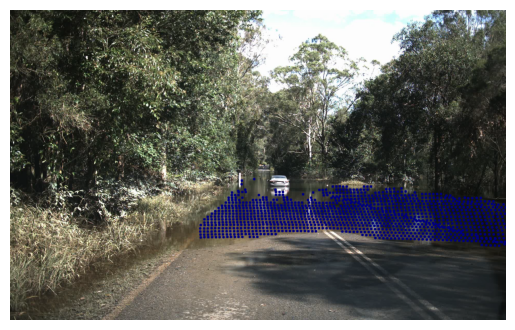

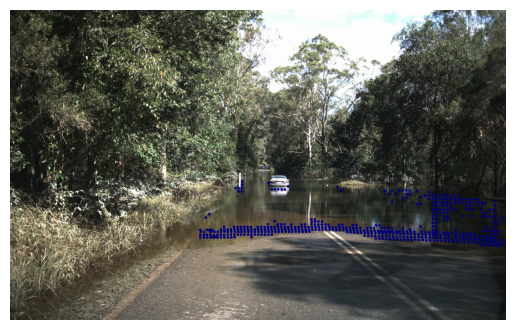

In [24]:
for timestamp in tqdm(timestamps[150:151]): # [100::]
    if verbose:
        print(f"Attempting pointcloud: {timestamp}.bin")

    # ── UTM proximity filter — check BEFORE loading point clouds ─────────
    utm_filename, image_filename = get_corr_files(timestamp, [utm_dir, image_dir])
    qry_utm = np.loadtxt(utm_filename)


    if has_ref:
        pc_dists = np.linalg.norm(ref_utms - qry_utm, axis=1)
        closest_dist = pc_dists[np.argmin(pc_dists)]
        if closest_dist > max_utm_dist:
            skipped_utm_too_far += 1
            if verbose:
                print(f"  Skipping {timestamp}: closest ref UTM {closest_dist:.2f}m away (> {max_utm_dist}m)")
            continue

    # ── Load revisit (query) scan ────────────────────────────────────────
    rev_pointcloud = PointCloud(f"{lidar_dir}/{timestamp}.bin", lidar_calib_file)
    rev_xyz        = rev_pointcloud.points[:, :3]
    rev_intensity  = rev_pointcloud.points[:, 3]
    rev_ground     = rev_pointcloud.ground_semantic

    valid = ~np.all(rev_xyz == 0, axis=1)
    rev_xyz, rev_intensity, rev_ground = rev_xyz[valid], rev_intensity[valid], rev_ground[valid]

    ranges = np.linalg.norm(rev_xyz, axis=1)
    valid  = (ranges < 80) & (rev_xyz[:, 2] < 1)
    rev_xyz, rev_intensity, rev_ground = rev_xyz[valid], rev_intensity[valid], rev_ground[valid]

    if has_ref:
        # ── Find Closest Ref Frame ────────────────────────────────────────────────

        ref_xyz, ref_intensity, ref_ground, _ref_cache, ref_utm, ref_pc_filename = mb_utils.get_closest_ref_frame(qry_utm, ref_utms, 
                                                                                                    ref_utm_fnames, _ref_cache, 
                                                                                                    ref_lidar_dir, lidar_calib_file, verbose)
        ref_pointcloud = PointCloud(ref_pc_filename, lidar_calib_file)

    f_temp         = image_filename.split("/")[-1]
    label_filename = f"{label_dir}/{f_temp}"
    image          = ImageData(image_filename, img_calib_file, label_filename)
    gt_mask        = np.zeros_like(image.image[:,:,0])
    pred_mask      = np.zeros_like(image.image[:,:,0])
    pointcloud     = PointCloud(f"{lidar_dir}/{timestamp}.bin",
                                lidar_calib_file)

    # ── Find Ground Truth Points ────────────────────────────────────────
    forward_angle_tol = 3
    max_lidar_range = 40
    has_gt = True

    if has_ref:
        # ── ICP Registration ────────────────────────────────────────────────

        icp_voxel_size = 0.3
        rev_pcd, ref_pcd, rev_xyz_aligned, rev_down, result_icp = mb_utils.icp_registration(rev_xyz, ref_xyz, qry_utm, ref_utm, icp_voxel_size, verbose)

        T_inv = np.linalg.inv(result_icp.transformation)

        gt_mask, gt_points = mb_utils.get_gt(ref_pointcloud, T_inv, image, cmap, full=False)
        
        print(f"gt_points shap: {gt_points.shape}")

        if len(gt_points) == 0 or gt_mask.max() == 0:
            has_gt = False
        else:
            gt_dist, closest_gt_point, _ = mb_utils.get_closest_dist(gt_points, forward_angle_tol)
    
            if gt_dist > max_lidar_range:
                has_gt = False
    
        gt_world = mb_utils.gt_points_to_world(gt_points, result_icp.transformation)
        
        gt_bev_mask = mb_utils.bev_points_to_blob_mask(
            gt_world, BEV_X_RANGE, BEV_Y_RANGE, BEV_RESOLUTION,
            point_radius=4, close_kernel_size=9)

    qry_label_mask, qry_label_points = mb_utils.get_gt(rev_pointcloud, None, image, cmap, full=False)

    pointcloud.points = gt_points
    pointcloud.points[:,3] = 255

    point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam() #, beam_id, azimuth
    img_vis, uv, valid_img, _ = image.project_points(all_points_cam, intensities_cam, cmap, valid_cam, colour_norm=255) #, beam_id, azimuth

    plt.figure()
    plt.imshow(img_vis[:,:,::-1])
    plt.axis('off')
    plt.savefig('../results/dry_labels_example.pdf', format='pdf', bbox_inches='tight', dpi=300)
    plt.show()

    pointcloud.points = qry_label_points
    pointcloud.points[:,3] = 255
    
    point_cam, distances_cam, intensities_cam, all_points_cam, valid_cam = pointcloud.points_ouster_to_cam() #, beam_id, azimuth
    img_vis, uv, valid_img, _ = image.project_points(all_points_cam, intensities_cam, cmap, valid_cam, colour_norm=255) #, beam_id, azimuth

    plt.figure()
    plt.imshow(img_vis[:,:,::-1])
    plt.axis('off')
    plt.savefig('../results/og_labels_example.pdf', format='pdf', bbox_inches='tight', dpi=300)
    plt.show()



In [ ]:
# voxel_size = 0.3

# gt_pointcloud = o3d.geometry.PointCloud()
# gt_pointcloud.points = o3d.utility.Vector3dVector(gt_points[:,:3])
# colors = plt.get_cmap("viridis")((gt_points[:,4]+1)/3)[:, :3]
# gt_pointcloud.colors = o3d.utility.Vector3dVector(colors)
# gt_pointcloud = gt_pointcloud.voxel_down_sample(voxel_size)
# gt_pointcloud = o3d.geometry.VoxelGrid.create_from_point_cloud(gt_pointcloud, voxel_size=voxel_size)
# gt_pointcloud.paint_uniform_color([0, 0, 1])  # blue

    # pcd = o3d.geometry.PointCloud()
    # pcd.points = o3d.utility.Vector3dVector(xyz)
    # pcd_down = pcd.voxel_down_sample(voxel_size)

# qry_pointcloud = o3d.geometry.PointCloud()
# qry_pointcloud.points = o3d.utility.Vector3dVector(rev_pointcloud.points[:,:3])
# qry_pointcloud.paint_uniform_color([0.5, 0.5, 0.5])  # gray
# qry_label_pointcloud = o3d.geometry.PointCloud()
# qry_label_pointcloud.points = o3d.utility.Vector3dVector(qry_label_points[:,:3])
# colors = plt.get_cmap("rainbow")((qry_label_points[:,4]+1)/3)[:, :3]
# qry_label_pointcloud.colors = o3d.utility.Vector3dVector(colors)
# # qry_label_pointcloud.paint_uniform_color([1, 0, 0])  # red
# o3d.visualization.draw_geometries([qry_label_pointcloud,])